# Reviewer validation report: IoT-71000-2026

**Verdict of this reproduction attempt: predictive results remain unvalidated.**
The confusion-matrix arithmetic is largely consistent. Public dataset metadata
and executable shape/gradient checks expose material reproducibility questions.
Real Sherlock training and author-model accuracy reproduction did not run because
data/model downloads were blocked and the six-class label mapping is unresolved.
This is not an accusation about the origin of the submitted results.

## What was actually executed

- Independently recomputed all class metrics from the manuscript's Figure 5(b),
  manually transcribed and visually checked against the proof.
- Compared those counts with Figure 4 and Table V.
- Read the original public Sherlock dataset publication and pinned IPAL event
  metadata; checked the semantic status of Generator Control maintenance.
- Executed eight code tests: full-width six-layer DistilBERT forward/backward,
  valid routed probabilities, benign masking, original-label preservation,
  published-count arithmetic, singleton attention and a multi-token control.
- Executed local CPU forward and gradient checks with random inputs. These are
  architecture tests, **not synthetic replacements for benchmark experiments**.
- Attempted Zenodo and GitHub-media dataset access, public pretrained-checkpoint
  access, and native authenticated Git LFS. The actual failure evidence is saved.

## Numerical consistency

| check                             | manuscript               | recomputed      | outcome                                                                  |
|:----------------------------------|:-------------------------|:----------------|:-------------------------------------------------------------------------|
| Multiclass accuracy               | 98.65%                   | 98.645990%      | Consistent to two decimal places                                         |
| Macro F1                          | 0.96 / 96.0%             | 95.762261%      | Consistent with F1 fraction rounded to 0.96; equals 95.8% at one decimal |
| Weighted F1                       | not separately specified | 98.668726%      | Different averaging, not the reported macro score                        |
| Matrix test support               | Figure 5(b)              | 8641            | Exactly equals all Figure 4 counts                                       |
| Separate binary-head accuracy/AUC | dual-head claim          | not recoverable | Require binary-head predictions and continuous scores                    |
| New model test accuracy           | 98.65%                   | NOT RUN         | No real-data training completed                                          |

The matrix contains 8,524 correct predictions among
8,641 rows. Macro F1 is 0.957622605; weighted
F1 is 0.986687259. Table V's 0.96 agrees with macro F1 rounded
to two decimals. Writing that rounded fraction as 96.0% instead of 95.8% is a
precision ambiguity, not by itself a substantive contradiction.

The lowest class F1s are Industroyer (0.9084) and GeneratorControl (0.9435),
whereas PDF p.11 says Industroyer and Control&Freeze. Table V also implies a
three-percentage-point macro-F1 improvement over the no-attention variant
(0.96 vs 0.93); the accompanying text says two. These are correctable numerical
description errors and do not establish invalid experimental predictions.

Collapsing the six-class matrix yields benign/attack counts
`[[7387, 91], [26, 1137]]`, with attack F1 0.951066.
This is a **derived collapse**, not an independently evaluated binary head.
All off-diagonal errors touch Benign; there are zero confusions between attack
families in this displayed matrix. To validate the dual-head claims, request
the separate binary head, family head, and routed end-to-end predictions.
ROC AUC cannot be recovered from the hard counts; the scores are required.

## Major questions for the authors

### 1. Label provenance and the additional attack class

The original Sherlock publication (Wagner et al., CODASPY 2025, Sections 3.4–3.5)
describes four attack families, and says maintenance events should be normal.
The pinned 01-Basic event catalog contains four malicious description families
and ten explicitly benign events. In particular, the catalog entry
`control center:Generator Control` has ID `16 (benign event)`.
The submitted manuscript instead lists GeneratorControl as a fifth attack family.

**Request:** provide the precise label-generation code and event IDs behind all
six classes. If a custom generator-control attack was added, provide its capture
and ground truth. If a legitimate maintenance event was relabeled, justify that
choice and evaluate the security false-positive implications. Until this is
resolved, a canonical five-class rerun is a different task and cannot validate
the six-class result. The provided loader refuses to invent this attack label.

Primary evidence: [pinned event catalog](https://raw.githubusercontent.com/ipal-ids/ipal_datasets/2fae8546757f82b4840a492cf6351d28f3727e60/Sherlock/ipal/01-Basic/test.events.json) and
[original dataset publication](https://github.com/ipal-ids/ipal_datasets/blob/2fae8546757f82b4840a492cf6351d28f3727e60/Sherlock/documentation/paper.pdf). No raw
measurement rows were available to verify their counts against this manuscript.

### 2. Transformer tokenization and fusion are not dimensionally specified

Equation 4 defines an F-to-768 projection. Reshaping 768 values into L tokens
each of width 768, as Equation 5 describes, forces L=1 unless another operation
adds values. The [CLS] token's origin and input embedding construction are not
given. A kernel-5 CNN over one transformer token cannot learn a neighborhood
across multiple tokens.

Equation 10 concatenates source vectors, then Equation 11 applies MHA without
giving its token axis. Under a literal singleton-token fusion, softmax has one
entry equal to 1, so query/key weights cannot adaptively choose among sources.
The executed full-width gradient check found maximum absolute fusion query/key
gradient **0.0**. A multi-token control
produced nonzero query/key gradients. This is a conditional mathematical result
about that interpretation, **not proof that the authors used it**.

**Request:** publish tensor shapes at every step (B,L,D), sequence construction,
whether tokens are features, feature groups or time steps, the actual pretrained
checkpoint, [CLS]/position handling, CNN topology, fusion query/key/value shapes,
and attention head count. Clarify whether there is one token or multiple source
tokens. `model.py` explicitly labels its defaults as hypotheses, rather than
silently repairing the missing architecture.

### 3. Split provenance, time dependence, and class-count figure

Figure 4 counts equal Figure 5 row totals exactly. This could mean Figure 4
shows test-only counts. It does **not** prove that training and test rows overlap.
If 8,641 is a 20% held-out set, the source table is roughly 43,205 rows;
`ceil(0.2 * 43204) = 8641`, so a 43,204-row export would also be compatible.
The exact source rows have not been downloaded to confirm this hypothesis.

The original Sherlock publication distinguishes 10-second measurement messages
from one-second exported observed-state records. The manuscript mentions the
former but does not specify which rows, resampling or temporal windows were
used. Stratified random row splits can place adjacent or repeated process states
and the same attack event in training and testing.

**Request:** provide dataset version/URL/checksum, feature inventory, excluded
label/event/time fields, source split selection, split indices, random seed,
sequence/window construction, and train-only scaling details. Clarify whether
Figure 4 is the full dataset or just test support. Add event-held-out or
chronological evaluation, exact/near-duplicate checks, and avoid overlapping
windows across splits. Leakage is a risk here, not an established accusation.

### 4. Multi-task loss, comparisons, and uncertainty

The binary/family weighting lambda, class weights, treatment of benign rows in
the family loss, focal-loss parameters, pretrained/frozen layers, scheduler,
model-selection metric and stochastic seed are absent or ambiguous. Four
variants are announced but five are listed. Comparative LSTM/Kalman and
DSE-BiLSTM implementations, preprocessing and a common split are not supplied.

**Request:** release configuration/code and predictions for all ablations and
baselines on the exact same held-out rows; report repeated seeds, confidence
intervals, separate binary and family scores, and per-class support. The original
Sherlock work recommends detected events, false alarms and time to detection,
including recovery handling. Point accuracy alone does not validate real-time
protection. Supply hardware, measured inference latency/throughput and memory.

## Scope and current blockers

No real-data model was trained; the main accuracy, ROC AUC, learning curves,
ablation rankings and comparative baselines therefore remain **unreproduced**.
Do not read the regenerated confusion plot as a newly trained result.

The independent literal architecture has 73,252,231 parameters.
Its local CPU timings in `architecture_checks.json` use random inputs and do not
establish the paper's efficiency, hardware usage or deployment feasibility.

Zenodo, the Sherlock site, GitHub media and Hugging Face returned proxy errors
under the current environment policy. Public GitHub metadata reads succeeded;
native Git LFS returned “Resource not accessible by integration.” Verified
dependencies installed successfully with signature/TLS checks intact. No new
secret is requested; the assets are public.

Network domain additions were saved in the environment draft, preserving the
existing policy. Review and save those changes in environment settings, then
publish the environment as requested by the product, and retry downloads.
Saving the draft itself did not change the running policy or publish it.
Label/architecture clarification remains necessary even after access works.

`README.md` gives reproducible commands and explicit assumptions. `train.py`
is ready to attempt the stated 30-epoch/early-stopping protocol once genuine
data and labeling prerequisites exist. Code tests passing does not validate
its experimental results or the manuscript.


,check,manuscript,recomputed,outcome
0,Multiclass accuracy,98.65%,98.645990%,Consistent to two decimal places
1,Macro F1,0.96 / 96.0%,95.762261%,Consistent with F1 fraction rounded to 0.96; e...
2,Weighted F1,not separately specified,98.668726%,"Different averaging, not the reported macro score"
3,Matrix test support,Figure 5(b),8641,Exactly equals all Figure 4 counts
4,Separate binary-head accuracy/AUC,dual-head claim,not recoverable,Require binary-head predictions and continuous...
5,New model test accuracy,98.65%,NOT RUN,No real-data training completed


,precision,recall,f1-score,support
ArpSpoof,0.979167,0.959184,0.969072,49.00000
Benign,0.996493,0.987831,0.992143,7478.00000
Control&Freeze,0.941176,0.986595,0.963351,373.00000
DriftOff,0.962766,0.975741,0.969210,371.00000
GeneratorControl,0.914062,0.975000,0.943548,120.00000
Industroyer,0.852632,0.972000,0.908411,250.00000
accuracy,0.986460,0.986460,0.986460,0.98646
macro avg,0.941049,0.976059,0.957623,8641.00000
weighted avg,0.987252,0.986460,0.986687,8641.00000


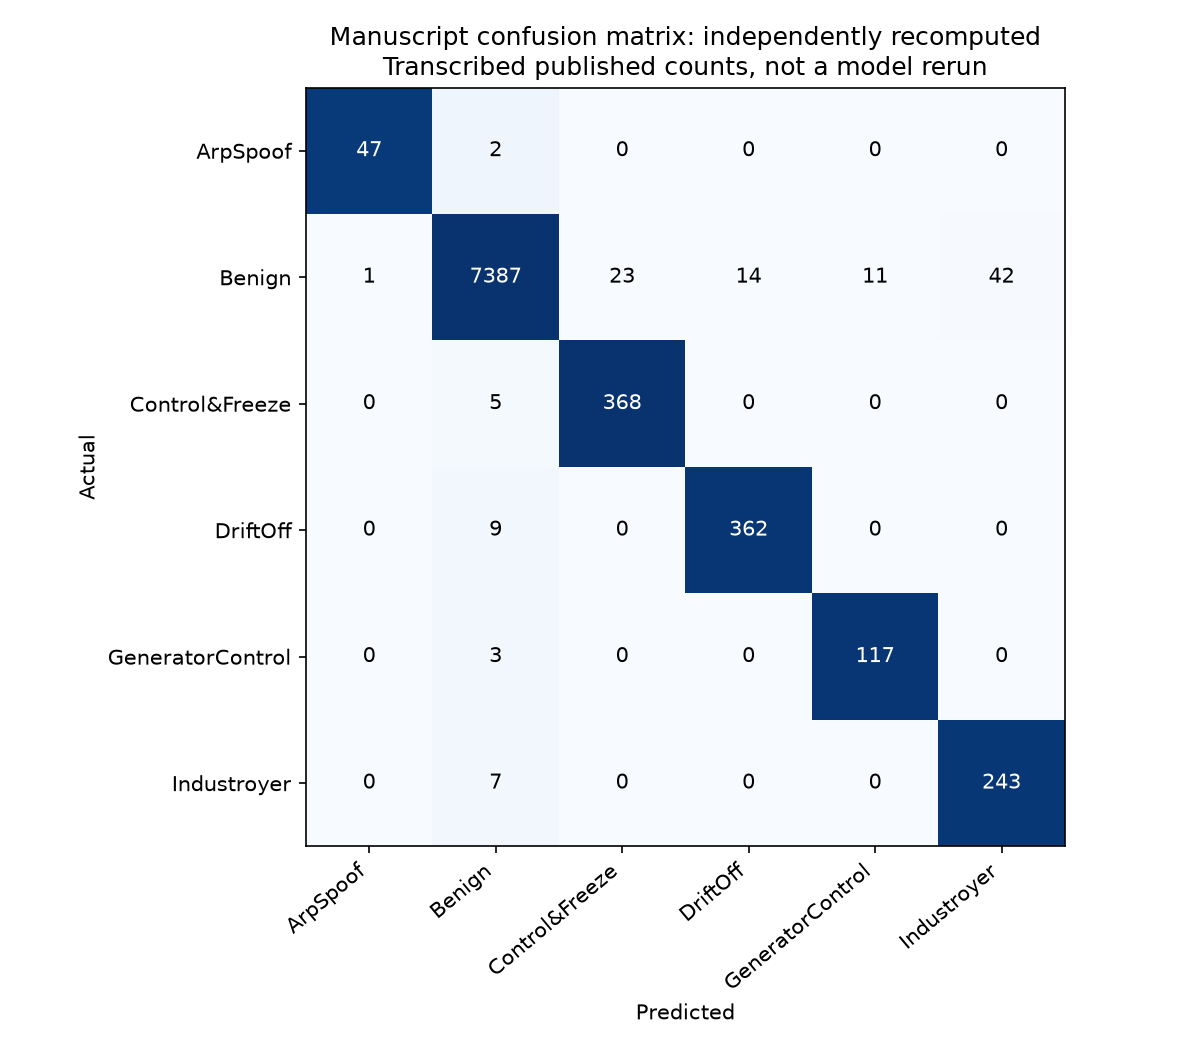

Real-data training: NOT RUN. Arithmetic audit and structural tests only.


In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image
root=Path.cwd()
display(pd.read_csv(root/'results/validation_summary.csv'))
display(pd.read_csv(root/'results/recomputed_classification_report.csv',index_col=0))
display(Image(filename=str(root/'figures/paper_matrix_audit.png')))
print('Real-data training: NOT RUN. Arithmetic audit and structural tests only.')